# 10 Cut types and how to mix them

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bsc-wdc/qdislib/blob/main/notebooks/10_cut_types.ipynb) [![Open in Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/bsc-wdc/qdislib/main?labpath=notebooks/10_cut_types.ipynb)

Qdislib has three kinds of cut. This notebook compares them on small circuits, then mixes them with `circuit_cutting`. All the costs here come from `cutting_overhead`, which runs nothing.

| Cut | Function | `gamma` | Needs |
|---|---|---|---|
| measure-and-prepare gate cut | `gate_cutting` | `1 + 2 abs(sin(phi))` per `rzz(phi)`; 3 for a CZ | mid-circuit measurement (or an extra qubit) |
| Hadamard gate cut | `gate_cutting_hadamard` | the same for one gate; `2**(k+1) - 1` for `k` CZ together | one ancilla per fragment |
| wire cut | `wire_cutting` | 4; 3 at a golden point | a measurement and a preparation |

In [1]:
# Installs Qdislib on Colab or Binder; does nothing where Qdislib 2 is installed.
try:
    import Qdislib
    assert Qdislib.__version__.startswith("2.")
except (ImportError, AssertionError):
    %pip install -q "qdislib[qibo,qiskit]>=2.0"

In [2]:
# Display helper, not part of Qdislib: renders one figure per value now, and shows them
# under a slider that works without a running kernel (so also on the documentation pages).
import base64, hashlib, io
from IPython.display import display
import matplotlib.pyplot as plt


def slider(render, values, label, start=0):
    frames = []
    for value in values:
        fig = render(value)
        buffer = io.BytesIO()
        fig.savefig(buffer, format="png", dpi=90, bbox_inches="tight")
        plt.close(fig)
        frames.append(base64.b64encode(buffer.getvalue()).decode())
    uid = "s" + hashlib.sha1((label + str(values)).encode()).hexdigest()[:10]
    html = f"""
    <div id="{uid}">
      <label>{label}: <b class="value">{values[start]}</b></label><br>
      <input type="range" min="0" max="{len(values) - 1}" value="{start}" style="width: min(100%, 420px)"><br>
      <img style="max-width: 100%" src="data:image/png;base64,{frames[start]}">
    </div>
    <script>(function () {{
      const root = document.getElementById("{uid}");
      const values = {[str(value) for value in values]};
      const frames = {frames};
      root.querySelector("input").addEventListener("input", function (event) {{
        const i = Number(event.target.value);
        root.querySelector(".value").textContent = values[i];
        root.querySelector("img").src = "data:image/png;base64," + frames[i];
      }});
    }})();</script>"""
    # The PNG is what static viewers without scripts (PDF, GitHub) show.
    display({"text/html": html, "image/png": frames[start]}, raw=True)

In [3]:
%matplotlib inline
import logging
import warnings

import numpy as np
from qiskit import QuantumCircuit
import Qdislib as qd

logging.getLogger("qibo.config").setLevel(logging.WARNING)  # Qibo logs its backend on every set-up


def two_blocks(gate="rzz", angle=0.5):
    """Two pairs of qubits joined by one gate."""
    qc = QuantumCircuit(4)
    qc.ry(0.7, range(4))
    qc.cz(0, 1)
    qc.cz(2, 3)
    if gate == "rzz":
        qc.rzz(angle, 1, 2)
    elif gate == "cp":
        qc.cp(angle, 1, 2)
    else:
        getattr(qc, gate)(1, 2)
    qc.ry(0.3, range(4))
    return qc


qc = two_blocks()
print(qc.draw(fold=100))

     ┌─────────┐   ┌─────────┐           
q_0: ┤ Ry(0.7) ├─■─┤ Ry(0.3) ├───────────
     ├─────────┤ │ └─────────┘┌─────────┐
q_1: ┤ Ry(0.7) ├─■───■────────┤ Ry(0.3) ├
     ├─────────┤     │ZZ(0.5) ├─────────┤
q_2: ┤ Ry(0.7) ├─■───■────────┤ Ry(0.3) ├
     ├─────────┤ │ ┌─────────┐└─────────┘
q_3: ┤ Ry(0.7) ├─■─┤ Ry(0.3) ├───────────
     └─────────┘   └─────────┘           


## A gate cut follows the gate's angle

A gate is cut as the `rzz` rotations it decomposes into: one for `cp`, `crz`, `cry`, `rxx`, `ryy`, `rzz`, up to three for a general gate. Each is cut at its own angle, with six terms. So a weak gate is cheap,
and CZ, equivalent to a rotation of `pi/2`, is the expensive case.

Move the slider: the cut gate's `gamma`, and the shots it asks for, `gamma**2`, relative to an uncut circuit.

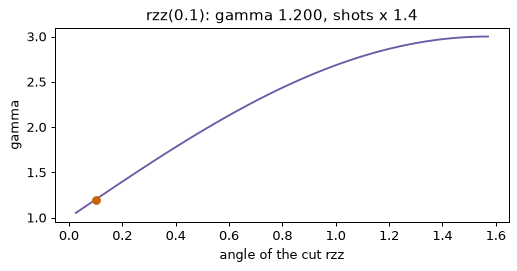

In [4]:
angles = np.linspace(0, np.pi / 2, 61)[1:]
gammas = [qd.cutting_overhead(two_blocks(angle=float(a)), {"gate": ["RZZ_7"]})["gamma"] for a in angles]


def render(phi):
    gamma = qd.cutting_overhead(two_blocks(angle=phi), {"gate": ["RZZ_7"]})["gamma"]
    fig, ax = plt.subplots(figsize=(6.5, 2.8))
    ax.plot(angles, gammas, color="#6f5aa6")
    ax.plot([phi], [gamma], "o", color="#c8640a")
    ax.set_xlabel("angle of the cut rzz")
    ax.set_ylabel("gamma")
    ax.set_title(f"rzz({phi}): gamma {gamma:.3f}, shots x {gamma**2:.1f}")
    return fig


slider(render, [0.05, 0.1, 0.2, 0.4, 0.8, 1.2, 1.57], "angle", start=1)

## The same value from every cut

Each cut reconstructs the same value, and with `shots=None` exactly. The three functions differ in what they run.

In [5]:
qc = two_blocks("cz")
print([f"{d.operation.name}_{i + 1}" for i, d in enumerate(qc.data) if d.operation.num_qubits == 2])
exact = qd.analytical_solution(qc, "ZZZZ")
print(f"exact    {exact:+.6f}")
print(f"gate     {qd.gate_cutting(qc, ['CZ_7'], 'ZZZZ', shots=None):+.6f}", qd.cutting_overhead(qc, {"gate": ["CZ_7"]}))
print(f"Hadamard {qd.gate_cutting_hadamard(qc, ['CZ_7'], 'ZZZZ', shots=None):+.6f}", qd.cutting_overhead(qc, {"hadamard": ["CZ_7"]}))
print(f"wire     {qd.wire_cutting(qc, [('CZ_6', 'CZ_7')], 'ZZZZ', shots=None):+.6f}", qd.cutting_overhead(qc, {"wire": [("CZ_6", "CZ_7")]}))

['cz_5', 'cz_6', 'cz_7']
exact    -0.079398
gate     -0.079398 {'subcircuits': 12, 'configurations': 6, 'fragments': 2, 'gamma': 3.0}
Hadamard -0.079398 {'subcircuits': 12, 'configurations': 6, 'fragments': 2, 'gamma': 3.0}
wire     -0.079398 {'subcircuits': 12, 'configurations': 6, 'fragments': 2, 'gamma': 3.0}


## When to use which

**Measure-and-prepare** needs no ancilla, so it is the first choice for gates with one interaction. Its fragments have a mid-circuit measurement, which simulators defer onto an extra qubit, and QPUs either run or defer it.

**Hadamard** uses one ancilla per fragment and no mid-circuit measurement. It is the cheaper one for a gate with several interactions, where the rotations' `gamma`s multiply. Qdislib warns then, and says how to ask for it. This one needs Qibo installed, even for a Qiskit circuit, which is why this notebook installs it:

In [6]:
qc = two_blocks("iswap")
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    print("measure-and-prepare:", qd.cutting_overhead(qc, {"gate": ["ISWAP_7"]}))
for warning in caught:
    print(warning.category.__name__ + ":", warning.message)
print("Hadamard:           ", qd.cutting_overhead(qc, {"hadamard": ["ISWAP_7"]}))
print("exact:", qd.analytical_solution(qc, "ZZZZ"), " Hadamard cut:", qd.gate_cutting_hadamard(qc, ["ISWAP_7"], "ZZZZ", shots=None))

measure-and-prepare: {'subcircuits': 72, 'configurations': 36, 'fragments': 2, 'gamma': 9.0}
Hadamard:            {'subcircuits': 56, 'configurations': 28, 'fragments': 2, 'gamma': 7.0}
exact: 0.1569966162326566  Hadamard cut: 0.15699661623265643


**Joint Hadamard.** Gates crossing one boundary can share one ancilla per fragment, even at different times: `gamma` `2**(k+1) - 1` instead of `3**k`, and one ancilla per side instead of `k`. This is the default; `joint=False` cuts each gate on its own. The shared ancilla has to stay coherent from the first gate to the last, so on hardware with short coherence separate cuts can be better.

In [7]:
def k_crossings(k):
    """Two blocks of k qubits, each connected, and k CZ gates between them."""
    qc = QuantumCircuit(2 * k)
    qc.ry(0.6, range(2 * k))
    for q in range(k - 1):
        qc.cz(q, q + 1)
        qc.cz(k + q, k + q + 1)
    first = len(qc.data) + 1
    for q in range(k):
        qc.cz(q, k + q)
    return qc, [f"CZ_{first + i}" for i in range(k)]


print(" k  gate gamma  joint gamma  gate circuits  joint circuits  separate Hadamard circuits")
for k in (1, 2, 3, 4):
    qc, names = k_crossings(k)
    gate = qd.cutting_overhead(qc, {"gate": names})
    joint = qd.cutting_overhead(qc, {"hadamard": names})
    separate = qd.cutting_overhead(qc, {"hadamard": names}, joint=False)
    print(f"{k:2d} {gate['gamma']:11.0f} {joint['gamma']:12.0f} {gate['subcircuits']:14d} {joint['subcircuits']:15d} {separate['subcircuits']:27d}")

 k  gate gamma  joint gamma  gate circuits  joint circuits  separate Hadamard circuits
 1           3            3             12              12                          12
 2           9            7             72              56                          72
 3          27           15            432             240                         432
 4          81           31           2592             992                        2592


**Wire cuts** split a qubit's timeline. They suit a circuit where a qubit passes state from one region to another. A **golden cut point** is a wire leaving a fragment whose state is real: only real gates such as `ry`, `cz`, `cx`, `h`, no gate cut, and every wire it receives golden too. Its `Y` terms are zero and are left out, so 6 terms and `gamma` 3 instead of 8 and 4. It is exact and automatic. A complex gate such as `rx` turns it off:

In [8]:
real = QuantumCircuit(4)
real.ry(0.5, range(4))
real.cz(0, 1)
real.cz(1, 2)
real.cz(2, 3)
cut = [("CZ_5", "CZ_6")]
print("real state:   ", qd.cutting_overhead(real, {"wire": cut}))

complex_ = real.copy()
complex_.rx(0.3, 0)
print("with an rx:   ", qd.cutting_overhead(complex_, {"wire": cut}))
print("both exact:   ", qd.wire_cutting(real, cut, "ZZZZ", shots=None), qd.analytical_solution(real, "ZZZZ"))

real state:    {'subcircuits': 12, 'configurations': 6, 'fragments': 2, 'gamma': 3.0}
with an rx:    {'subcircuits': 16, 'configurations': 8, 'fragments': 2, 'gamma': 4.0}
both exact:    0.5931327983656767 0.5931327983656769


## `optimized=True`: a sum instead of a product

By default every fragment runs for every term of the combined decomposition. With `optimized=True` each fragment runs once per setting of *the cuts that touch it* and is reused in every term, so
the circuit count is a sum over fragments rather than a product over cuts. Cut wires leaving the same fragment are also measured together (`2**k + 1` circuits for `k` wires instead of `3**k`; `joint=False` for the per-wire circuits, which use no extra entangling gates).
The value is the same up to shot noise.

In [9]:
print("gate cuts between two fragments")
for k in (1, 2, 3, 4):
    qc, names = k_crossings(k)
    print(f"  k={k}: standard {qd.cutting_overhead(qc, {'gate': names})['subcircuits']:5d}   optimized {qd.cutting_overhead(qc, {'gate': names}, optimized=True)['subcircuits']:5d}")

qc, names = k_crossings(2)
for options in ({}, {"optimized": True}):
    print(options, qd.gate_cutting(qc, names, "ZZZZ", shots=4000, seed=1, **options))
print("exact", qd.analytical_solution(qc, "ZZZZ"))

gate cuts between two fragments
  k=1: standard    12   optimized    10
  k=2: standard    72   optimized    50
  k=3: standard   432   optimized   250
  k=4: standard  2592   optimized  1250


{} 0.46506420312499996


{'optimized': True} 0.4671259999999999
exact 0.464004662795681


## Any mix: `circuit_cutting`

`circuit_cutting` takes any number of each kind on one circuit: a dict with any of `"gate"`, `"hadamard"`, `"wire"`, what `find_cut(..., mixed=True)` returns, or a list of gate names and wire edges (with `hadamard=True` for its gates to be Hadamard cuts). It has the same four forms as the other cuts: `circuit_cutting`,
`circuit_cutting_subcircuits`, `circuit_cutting_sampling` and `circuit_cutting_sampling_subcircuits`. It is also the one engine the other functions run on.

['cz_7', 'cz_8', 'cz_9', 'cz_10', 'cz_11', 'cz_18', 'cz_19']


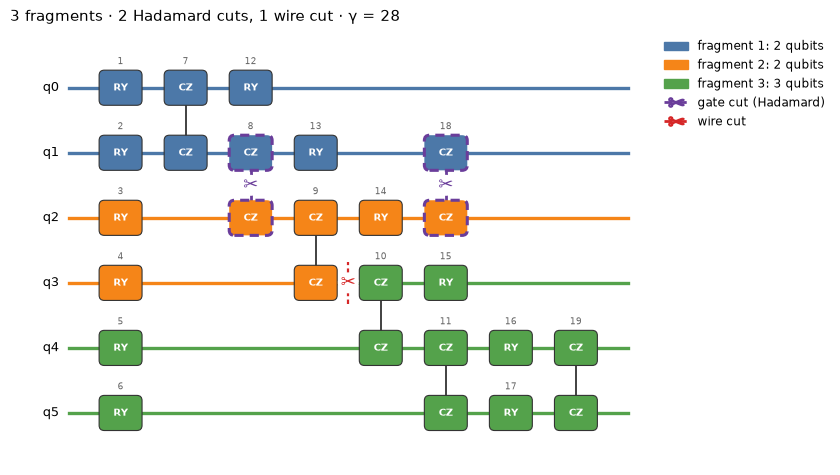

In [10]:
qc = QuantumCircuit(6)
qc.ry(0.6, range(6))
for q in range(5):
    qc.cz(q, q + 1)
qc.ry(0.3, range(6))
qc.cz(1, 2)
qc.cz(4, 5)
print([f"{d.operation.name}_{i + 1}" for i, d in enumerate(qc.data) if d.operation.num_qubits == 2])

cuts = {"hadamard": ["CZ_8", "CZ_18"], "wire": [("CZ_9", "CZ_10")]}
qd.draw_cut(qc, cuts);

In [11]:
print(qd.cutting_overhead(qc, cuts))
print("optimized:", qd.cutting_overhead(qc, cuts, optimized=True))

exact = qd.analytical_solution(qc, "Z" * 6)
print(f"exact pieces {qd.circuit_cutting(qc, cuts, 'Z' * 6, shots=None):+.6f}   exact {exact:+.6f}")
print(f"with shots   {qd.circuit_cutting(qc, cuts, 'Z' * 6, shots=4000, seed=1, optimized=True):+.4f}")

dist = qd.circuit_cutting_sampling(qc, cuts, shots=None, qubits=[0, 3])
print("marginal on q0, q3:", dist)

subs = qd.circuit_cutting_subcircuits(qc, cuts, "Z" * 6, optimized=True)
print(subs)
print(f"three-step   {subs.reconstruct([qd.expectation_value(s, shots=4000, seed=i) for i, s in enumerate(subs)]):+.4f}")

{'subcircuits': 672, 'configurations': 224, 'fragments': 3, 'gamma': 28.0}
optimized: {'subcircuits': 116, 'configurations': 224, 'fragments': 3, 'gamma': 28.0}


exact pieces -0.020519   exact -0.020519


with shots   -0.0180


marginal on q0, q3: {'00': 0.6911750546819923, '10': 0.14622969547191922, '01': 0.13420246384170517, '11': 0.028392786004383358}
<CutCircuits: 116 subcircuits, 3 fragments, Hadamard ['CZ_8', 'CZ_18']; wire [('CZ_9', 'CZ_10')], gamma 28, observable ZZZZZZ>


three-step   -0.0156


## How the cost grows

Two fragments and `k` CZ cuts between them. The table is computed here by `cutting_overhead`, so it can be changed to your circuit.

In [12]:
print(" k | gate  gate-opt  Hadamard | gamma: gate  Hadamard")
for k in (1, 2, 3, 4):
    qc, names = k_crossings(k)
    g = qd.cutting_overhead(qc, {"gate": names})
    o = qd.cutting_overhead(qc, {"gate": names}, optimized=True)
    h = qd.cutting_overhead(qc, {"hadamard": names})
    print(f"{k:2d} | {g['subcircuits']:4d} {o['subcircuits']:8d} {h['subcircuits']:9d} | {g['gamma']:11.0f} {h['gamma']:9.0f}")

 k | gate  gate-opt  Hadamard | gamma: gate  Hadamard
 1 |   12       10        12 |           3         3
 2 |   72       50        56 |           9         7
 3 |  432      250       240 |          27        15
 4 | 2592     1250       992 |          81        31


## Every cut has to separate

A cut is valid only if its two sides end up in different fragments, judged with all the other cuts applied. Two gates across one boundary, or a gate cut that comes loose only together with a wire cut, are valid. A cut that an uncut path bypasses raises `InvalidCutError`, even when the other cuts do split the circuit. See notebook 03.

Next: **11 Shots and error bars**.